<a href="https://colab.research.google.com/github/wuqy052/SRS_variability_stability/blob/main/code/Main_analysis_SRS_Variability_Stability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font size="4"> Main analysis script for **Variability and stability of autistic traits in the general population: a systematic comparison between online and in-lab samples** </font>

<font size="3">By Caroline Charpentier and Qianying Wu </font>

In [1]:
# load packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import pearsonr, ttest_ind, zscore, ttest_rel, norm, chi2_contingency
import statsmodels.formula.api as smf
from datetime import datetime

# Load data



In [2]:
# set path to be the path of the github repo 'SRS_variability_stability'
root = os.path.dirname(os.getcwd())

In [ ]:
# load full cross-sectional dataset
data_merged_nodupl_excl = pd.read_csv(root + '/data/cross_sectional_excl.csv',index_col=0)

In [4]:
# load SRS item description file
SRS_item_description = pd.read_csv(root + '/data/SRS_item_description.csv')

In [5]:
# load test-retest dataset
t_rt_cutoff = pd.read_csv(root + '/data/test_retest_excl.csv')
# load ICC
ICC_all = pd.read_csv(root + '/results/ICC_both.csv')

# Variability in SRS scores

## Summary of variables
Print the descriptive stats for demographic and questionnaire variables, for online and in-lab samples, respectively. Also perform statistal tests.

In [6]:
#function to calculate effect size
def cohen_d(sample1, sample2):
    """
    Calculate Cohen's d for two independent samples, as well as degrees of freedom for unequal variances (Welch's t-test).

    Parameters:
    sample1 (array-like): First sample data.
    sample2 (array-like): Second sample data.

    Returns:
    float: Cohen's d value.
    """
    # Convert inputs to numpy arrays
    sample1 = np.array(sample1)
    sample2 = np.array(sample2)

    # Calculate the means and standard deviations
    mean1, mean2 = np.mean(sample1), np.mean(sample2)
    std1, std2 = np.std(sample1, ddof=1), np.std(sample2, ddof=1)

    # Calculate the pooled standard deviation
    n1, n2 = len(sample1), len(sample2)
    pooled_std = np.sqrt(((n1 - 1) * std1**2 + (n2 - 1) * std2**2) / (n1 + n2 - 2))

    # Calculate Cohen's d
    cohens_d = (mean1 - mean2) / pooled_std

    # Calculate df
    df_unequal = ((std1**2 / n1) + (std2**2 / n2))**2 / \
             (((std1**2 / n1)**2 / (n1 - 1)) + ((std2**2 / n2)**2 / (n2 - 1)))

    return cohens_d, df_unequal

In [7]:
def summary_var(var):
  sample_lab = data_merged_nodupl_excl[data_merged_nodupl_excl['format']=='In lab'][var].dropna()
  sample_online = data_merged_nodupl_excl[data_merged_nodupl_excl['format']=='Online'][var].dropna()
  ttest_result = ttest_ind(sample_lab, sample_online, equal_var=False)
  d, dfu = cohen_d(sample_lab, sample_online)
  print("Online, mean", var, "=", np.mean(np.mean(sample_online)), ", SD =", np.std(sample_online), ", missing =", np.sum(sample_online.isna()))
  print("In-lab, mean", var, "=", np.mean(sample_lab), ", SD =", np.std(sample_lab), ", missing =", np.sum(sample_lab.isna()))
  print("==========================")
  print(f"T-statistic (unequal variances): {ttest_result.statistic}")
  print(f"df (Welch's t-test): {ttest_result.df}")
  print(f"P-value (unequal variances): {ttest_result.pvalue}")
  print(f"Effect size Cohen's d (unequal variances): {d}")
  print('In lab N =', sample_lab.count())
  print('Online N =', sample_online.count())
  print(ttest_result.confidence_interval(confidence_level=0.95))

Gender

In [11]:
#chi-square test for gender by format
contingency_table = pd.crosstab(data_merged_nodupl_excl['format'], data_merged_nodupl_excl['Gender_recode'])
chi2, p, dof, expected = chi2_contingency(contingency_table)
print(contingency_table)
print(f"Chi-Square statistic: {chi2}")
print(f"P-value: {p}")
print(f"Degrees of freedom: {dof}")
print("Expected frequencies:")
print(expected)

Gender_recode     M  NB     W
format                       
In lab          146  15   266
Online         1037  38  1246
Chi-Square statistic: 20.652593701986667
P-value: 3.2760178476509896e-05
Degrees of freedom: 2
Expected frequencies:
[[ 183.8213246     8.23544396  234.94323144]
 [ 999.1786754    44.76455604 1277.05676856]]


Age

In [12]:
summary_var('age')

Online, mean age = 34.67444876783398 , SD = 12.054026312143302 , missing = 0
In-lab, mean age = 32.1260162601626 , SD = 11.872817470967984 , missing = 0
T-statistic (unequal variances): -4.307999464377649
df (Welch's t-test): 722.141118432351
P-value (unequal variances): 1.8754854612596863e-05
Effect size Cohen's d (unequal variances): -0.21189740987465225
In lab N = 492
Online N = 2313
ConfidenceInterval(low=np.float64(-3.7098118248119514), high=np.float64(-1.387053190530806))


SRS total raw score

In [10]:
summary_var('SRS')

Online, mean SRS = 62.575471698113205 , SD = 30.425990098779888 , missing = 0
In-lab, mean SRS = 43.78947368421053 , SD = 24.62036060668391 , missing = 0
T-statistic (unequal variances): -14.72933246872359
df (Welch's t-test): 844.285222795297
P-value (unequal variances): 7.120505089888031e-44
Effect size Cohen's d (unequal variances): -0.6367246549283859
In lab N = 494
Online N = 2332
ConfidenceInterval(low=-21.289352387298532, high=-16.282643640506823)


STAI-T total score

In [13]:
summary_var('STAI_trait')

Online, mean STAI_trait = 44.98134991119005 , SD = 12.565515991739593 , missing = 0
In-lab, mean STAI_trait = 41.64926931106472 , SD = 11.887000780949855 , missing = 0
T-statistic (unequal variances): -5.509630256093684
df (Welch's t-test): 723.1110982812479
P-value (unequal variances): 5.0028997282489346e-08
Effect size Cohen's d (unequal variances): -0.26755652913186345
In lab N = 479
Online N = 2252
ConfidenceInterval(low=np.float64(-4.5194029883799285), high=np.float64(-2.144758211870732))


LSAS total score

In [14]:
summary_var('LSAS')

Online, mean LSAS = 57.60556383507203 , SD = 29.778189921067817 , missing = 0
In-lab, mean LSAS = 38.091684434968016 , SD = 27.120243093224662 , missing = 0
T-statistic (unequal variances): -13.75608129455258
df (Welch's t-test): 753.505182763219
P-value (unequal variances): 1.4138317393067778e-38
Effect size Cohen's d (unequal variances): -0.6658609438775239
In lab N = 469
Online N = 2013
ConfidenceInterval(low=np.float64(-22.29868656680473), high=np.float64(-16.729072233403304))


BDI total score

In [15]:
summary_var('BDI')

Online, mean BDI = 13.802397868561279 , SD = 11.805917681248141 , missing = 0
In-lab, mean BDI = 9.588726513569938 , SD = 9.680919736147557 , missing = 0
T-statistic (unequal variances): -8.295876211578902
df (Welch's t-test): 810.4183203565566
P-value (unequal variances): 4.476251020935409e-16
Effect size Cohen's d (unequal variances): -0.3674948972263856
In lab N = 479
Online N = 2252
ConfidenceInterval(low=np.float64(-5.210672316835732), high=np.float64(-3.2166703931469507))


Date of data collection

In [16]:
data_merged_nodupl_excl['date'] = pd.to_datetime(data_merged_nodupl_excl['date'], errors='coerce')
data_merged_nodupl_excl['year'] = data_merged_nodupl_excl['date'].dt.year
data_merged_nodupl_excl[data_merged_nodupl_excl['format']=='Online']['year'].value_counts()

/var/folders/5q/slj33l6j3t3bg7dm3cbt6r500000gn/T/ipykernel_86046/2472735470.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data_merged_nodupl_excl['date'] = pd.to_datetime(data_merged_nodupl_excl['date'], errors='coerce')


year
2020    1024
2022     567
2021     473
2023     190
2024      78
Name: count, dtype: int64

In [17]:
data_merged_nodupl_excl[data_merged_nodupl_excl['format']=='In lab']['year'].value_counts()

year
2021    196
2022    137
2023    113
2020     31
2015     10
2019      5
2014      1
2018      1
Name: count, dtype: int64

In [18]:
#chi-square test for year by format
data_merged_nodupl_excl.loc[data_merged_nodupl_excl['year'] < 2020, ['year_group']] = '<2020'
data_merged_nodupl_excl.loc[(data_merged_nodupl_excl['year'] == 2020) | (data_merged_nodupl_excl['year_group'] == 2021), ['year_group']] = '2020-2021'
data_merged_nodupl_excl.loc[data_merged_nodupl_excl['year'] > 2021, ['year_group']] = '>2021'
contingency_table = pd.crosstab(data_merged_nodupl_excl['format'], data_merged_nodupl_excl['year_group'])
chi2, p, dof, expected = chi2_contingency(contingency_table)
print(contingency_table)
print(f"Chi-Square statistic: {chi2}")
print(f"P-value: {p}")
print(f"Degrees of freedom: {dof}")
print("Expected frequencies:")
print(expected)

year_group  2020-2021  <2020  >2021
format                             
In lab             31     17    250
Online           1024      0    835
Chi-Square statistic: 288.4437404142886
P-value: 2.3186628261617667e-63
Degrees of freedom: 2
Expected frequencies:
[[145.75336115   2.34863236 149.89800649]
 [909.24663885  14.65136764 935.10199351]]


## Online vs. In-lab SRS score differences

### Overall score difference

Text(0.5, 1.0, 'After careless exclusions, N=2826')

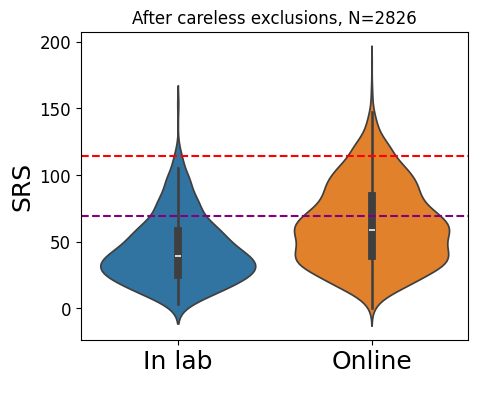

In [19]:
#plot distributions for the two groups
fig,ax = plt.subplots(figsize=(5,4))
sns.violinplot(data=data_merged_nodupl_excl, x="format", y="SRS", hue="format",ax=ax)
plt.axhline(y=69, color='purple', linestyle='--')
plt.axhline(y=114, color='red', linestyle='--')
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=12)
ax.set_ylabel('SRS',fontsize=18)
ax.set_xlabel(' ')
ax.set_title('After careless exclusions, N=' + str(len(data_merged_nodupl_excl)))

In [20]:
#run t-test for independent samples, assuming unequal variance
summary_var('SRS')

Online, mean SRS = 62.575471698113205 , SD = 30.425990098779888 , missing = 0
In-lab, mean SRS = 43.78947368421053 , SD = 24.620360606683928 , missing = 0
T-statistic (unequal variances): -14.72933246872359
df (Welch's t-test): 844.285222795297
P-value (unequal variances): 7.120505089888031e-44
Effect size Cohen's d (unequal variances): -0.6367246549283859
In lab N = 494
Online N = 2332
ConfidenceInterval(low=np.float64(-21.289352387298532), high=np.float64(-16.282643640506823))


### Specific SRS items/subscales/factors driving the difference

In [21]:
data_merged_nodupl_excl = data_merged_nodupl_excl.rename(columns = {'SRS_1_1': 'SRS_1', 'SRS_1_2': 'SRS_2', 'SRS_1_3': 'SRS_3', 'SRS_1_4': 'SRS_4', 'SRS_1_5': 'SRS_5', 'SRS_1_6': 'SRS_6', 'SRS_1_7': 'SRS_7',
                              'SRS_1_8': 'SRS_8', 'SRS_1_9': 'SRS_9', 'SRS_1_10': 'SRS_10', 'SRS_2_1': 'SRS_11', 'SRS_2_2': 'SRS_12', 'SRS_2_3': 'SRS_13', 'SRS_2_4': 'SRS_14',
                              'SRS_2_5': 'SRS_15', 'SRS_2_6': 'SRS_16', 'SRS_2_7': 'SRS_17', 'SRS_2_8': 'SRS_18', 'SRS_2_9': 'SRS_19',  'SRS_2_10': 'SRS_20', 'SRS_3_1': 'SRS_21',
                              'SRS_3_2': 'SRS_22', 'SRS_3_3': 'SRS_23', 'SRS_3_4': 'SRS_24', 'SRS_3_5': 'SRS_25', 'SRS_3_6': 'SRS_26', 'SRS_3_7': 'SRS_27', 'SRS_3_8': 'SRS_28',
                              'SRS_3_9': 'SRS_29', 'SRS_3_10': 'SRS_30', 'SRS_4_1': 'SRS_31', 'SRS_4_2': 'SRS_32', 'SRS_4_3': 'SRS_33', 'SRS_4_4': 'SRS_34', 'SRS_4_5': 'SRS_35',
                              'SRS_4_6': 'SRS_36', 'SRS_4_7': 'SRS_37', 'SRS_4_8': 'SRS_38', 'SRS_4_9': 'SRS_39', 'SRS_4_10': 'SRS_40', 'SRS_5_1': 'SRS_41', 'SRS_5_2': 'SRS_42',
                              'SRS_5_3': 'SRS_43', 'SRS_5_4': 'SRS_44', 'SRS_5_5': 'SRS_45', 'SRS_5_6': 'SRS_46', 'SRS_5_7': 'SRS_47', 'SRS_5_8': 'SRS_48', 'SRS_5_9': 'SRS_49',
                              'SRS_5_10': 'SRS_50', 'SRS_6_1': 'SRS_51', 'SRS_6_2': 'SRS_52', 'SRS_6_3': 'SRS_53', 'SRS_6_4': 'SRS_54', 'SRS_6_5': 'SRS_55', 'SRS_6_6': 'SRS_56',
                              'SRS_6_7': 'SRS_57', 'SRS_6_8': 'SRS_58', 'SRS_6_9': 'SRS_59', 'SRS_6_10': 'SRS_60', 'SRS_7_1': 'SRS_61', 'SRS_7_2': 'SRS_62', 'SRS_7_3': 'SRS_63',
                              'SRS_7_4': 'SRS_64', 'SRS_7_5': 'SRS_65'})

Create a data frame that summarizes, for each SRS item, the mean for online participants, the mean for in-lab participants, and the statistics of the in-lab vs online differences (t-test, cohen's d)

In [22]:
item_names = []
mean_item_online = []
mean_item_inlab = []
t_stat_all = []
df_all = []
p_value_all = []
d_all = []
d_rev_all = []
reverse_coded_fields = ['SRS_3', 'SRS_7', 'SRS_11', 'SRS_12', 'SRS_15', 'SRS_17', 'SRS_21', 'SRS_22', 'SRS_26', 'SRS_32', 'SRS_38', 'SRS_40', 'SRS_43', 'SRS_45', 'SRS_48']

for n in range(1,66):
  col_name = 'SRS_'+ str(n)
  sample1 = data_merged_nodupl_excl[data_merged_nodupl_excl['format']=='Online'][col_name].dropna()
  sample2 = data_merged_nodupl_excl[data_merged_nodupl_excl['format']=='In lab'][col_name].dropna()
  t_stat, p_value = ttest_ind(sample1, sample2, equal_var=False)
  d, df = cohen_d(sample1, sample2)

  item_names.append(col_name)
  mean_item_inlab.append(np.mean(sample1))
  mean_item_online.append(np.mean(sample2))
  t_stat_all.append(t_stat)
  df_all.append(df)
  p_value_all.append(p_value)
  d_all.append(d)
  if col_name in reverse_coded_fields:
    d_rev_all.append(-d)
  else:
    d_rev_all.append(d)

df_item_diff = pd.DataFrame(data = {'SRS_item': item_names, 'In lab mean': mean_item_inlab, 'Online mean': mean_item_online, 'T': t_stat_all, 'df': df_all, 'p': p_value_all, 'Cohens_d': d_all, 'Cohens_d_rev': d_rev_all})

Merge with SRS item description for more info

In [23]:
SRS_item_description['Factor_OLpaper'] = SRS_item_description['Factor_OLpaper'].astype('Int64')
SRS_item_description['Factor_simplified'] = SRS_item_description['Factor_simplified'].astype('Int64')

df_item_diff = pd.merge(df_item_diff, SRS_item_description, on='SRS_item', how='left')
df_item_diff = df_item_diff.drop(columns=['index'])

In [24]:
#perform FDR correction
df_item_diff = df_item_diff.sort_values(by='p', ascending=True).reset_index(drop=True)
for n in range(1,66):
  df_item_diff.loc[n-1,'pFDR'] = 0.05 * n / 65
  df_item_diff.loc[n-1,'isSigFDR'] = df_item_diff.loc[n-1,'p'] <= df_item_diff.loc[n-1,'pFDR']

In [43]:
#save data
df_item_diff.to_csv(root + '/results/item_online_inlab_diff_data.csv')

In [25]:
# show the largest differences for comparison
df_item_diff.sort_values(by='Cohens_d_rev', ascending=False, inplace=True)
df_item_diff.head(8)

,SRS_item,In lab mean,Online mean,T,df,p,Cohens_d,Cohens_d_rev,question_text,subscale,is_rev,Factor_simplified,Factor_OLpaper,pFDR,isSigFDR
0,SRS_64,1.610206,0.967611,13.360615,770.493008,9.018726e-37,0.619941,0.619941,I am much more tense in social settings than w...,mot,no,2,2,0.000769,True
3,SRS_6,1.581475,1.099190,11.481433,775.505910,2.727448e-28,0.529858,0.529858,I would rather be alone than with others.,mot,no,2,2,0.003077,True
2,SRS_57,1.382504,0.852227,11.705473,803.134500,2.473263e-29,0.525186,0.525186,I tend to isolate myself.,com,no,2,2,0.002308,True
4,SRS_1,1.578045,1.040486,11.176919,771.385026,5.505404e-27,0.518111,0.518111,I am much more uncomfortable in social situati...,mot,no,2,2,0.003846,True
1,SRS_33,0.924957,0.463563,12.544607,938.073132,1.752971e-33,0.506145,0.506145,"My behavior is socially awkward, even when I a...",com,no,<NA>,5,0.001538,True
8,SRS_23,1.494854,0.995951,10.499413,760.004469,3.572427e-24,0.492923,0.492923,I do not join group activities or social event...,mot,no,2,2,0.006923,True
5,SRS_27,1.269726,0.809717,11.003174,842.518779,2.096201e-26,0.476360,0.476360,I avoid starting social interactions with othe...,mot,no,2,2,0.004615,True
12,SRS_59,1.118782,0.684211,9.613735,765.183720,9.818351e-21,0.448711,0.448711,I am more suspicious than most people.,cog,no,8,8,0.010000,True


## Individual differences in SRS scores beyond the study format


### Main glm

Run a glm predicting SRS from as many variables as possible given what we have (exclude variables with too many missing data):
* format (none missing)
* BDI (95 missing)
* LSAS (344 missing)
* Trait anxiety (95 missing)
* Gender_recode (78 missing)
* age (21 missing)
* date_ordinal (none missing)

In [26]:
df_glm = data_merged_nodupl_excl[['SRS', 'format', 'BDI', 'LSAS', 'STAI_trait', 'Gender_recode', 'age', 'date_ordinal']].dropna()
model = smf.ols('SRS ~ format + scale(BDI) + scale(LSAS) + scale(STAI_trait) +  C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)',
                data=df_glm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    SRS   R-squared:                       0.551
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     368.6
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:33:47   Log-Likelihood:                -10672.
No. Observations:                2414   AIC:                         2.136e+04
Df Residuals:                    2405   BIC:                         2.141e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------

### Variance partition analysis

In [27]:
# Fit a reduced model, excluding each regressor
reduced_model_format = smf.ols('SRS ~ scale(BDI) + scale(LSAS) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_BDI = smf.ols('SRS ~ format + scale(LSAS) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_LSAS = smf.ols('SRS ~ format + scale(BDI) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_STAItrait = smf.ols('SRS ~ format + scale(BDI) + scale(LSAS) + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_gender = smf.ols('SRS ~ format + scale(BDI) + scale(LSAS) + scale(STAI_trait) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_age = smf.ols('SRS ~ format + scale(BDI) + scale(LSAS) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W"))  + scale(date_ordinal)', data=df_glm).fit()
reduced_model_date = smf.ols('SRS ~ format + scale(BDI) + scale(LSAS) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(age)', data=df_glm).fit()

# Extract R-squared for all models
r2_full = model.rsquared
r2_reduced_format = reduced_model_format.rsquared
r2_reduced_BDI = reduced_model_BDI.rsquared
r2_reduced_LSAS = reduced_model_LSAS.rsquared
r2_reduced_STAItrait = reduced_model_STAItrait.rsquared
r2_reduced_gender = reduced_model_gender.rsquared
r2_reduced_age = reduced_model_age.rsquared
r2_reduced_date = reduced_model_date.rsquared

# Calculate partial r-squared
partial_r2_format = (r2_full - r2_reduced_format) / (1 - r2_reduced_format)
partial_r2_BDI = (r2_full - r2_reduced_BDI) / (1 - r2_reduced_BDI)
partial_r2_LSAS = (r2_full - r2_reduced_LSAS) / (1 - r2_reduced_LSAS)
partial_r2_STAItrait = (r2_full - r2_reduced_STAItrait) / (1 - r2_reduced_STAItrait)
partial_r2_gender = (r2_full - r2_reduced_gender) / (1 - r2_reduced_gender)
partial_r2_age = (r2_full - r2_reduced_age) / (1 - r2_reduced_age)
partial_r2_date = (r2_full - r2_reduced_date) / (1 - r2_reduced_date)

print(f'Partial R-squared for format: {partial_r2_format:.3f}')
print(f'Partial R-squared for BDI: {partial_r2_BDI:.3f}')
print(f'Partial R-squared for LSAS: {partial_r2_LSAS:.3f}')
print(f'Partial R-squared for STAI trait: {partial_r2_STAItrait:.3f}')
print(f'Partial R-squared for gender: {partial_r2_gender:.3f}')
print(f'Partial R-squared for age: {partial_r2_age:.3f}')
print(f'Partial R-squared for date: {partial_r2_date:.3f}')

Partial R-squared for format: 0.011
Partial R-squared for BDI: 0.041
Partial R-squared for LSAS: 0.139
Partial R-squared for STAI trait: 0.037
Partial R-squared for gender: 0.051
Partial R-squared for age: 0.004
Partial R-squared for date: 0.009


Specifically look at how much of the variance explained by format in a simple SRS ~ format model is now explained by other factors in the new model:

In [28]:
simple_model_format = smf.ols('SRS ~ format', data=df_glm).fit()
intercept_model = smf.ols('SRS ~ 1', data=df_glm).fit()
r2_simple_format = simple_model_format.rsquared
r2_intercept = intercept_model.rsquared
partial_r2_format_simple = (r2_simple_format - r2_intercept) / (1 - r2_simple_format)
print(f'Partial R-squared for format vs intercept: {partial_r2_format_simple:.3f}')

Partial R-squared for format vs intercept: 0.058


Assessing how much of the internalizing symptoms specifically contribute to this variance explained:

In [29]:
# Assessing partial R-squared for format in models with and without internalizing symptoms
reduced_model_internalizing = smf.ols('SRS ~ format + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_format_internalizing = smf.ols('SRS ~ C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_dem = smf.ols('SRS ~ format + scale(BDI) + scale(LSAS) + scale(STAI_trait)', data=df_glm).fit()
reduced_model_format_dem = smf.ols('SRS ~ scale(BDI) + scale(LSAS) + scale(STAI_trait)', data=df_glm).fit()
reduced_model_format_BDI = smf.ols('SRS ~ scale(LSAS) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_format_LSAS = smf.ols('SRS ~ scale(BDI) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_format_STAItrait = smf.ols('SRS ~ scale(BDI) + scale(LSAS) + C(Gender_recode, Treatment(reference="W")) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_format_gender = smf.ols('SRS ~ scale(BDI) + scale(LSAS) + scale(STAI_trait) + scale(age) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_format_age = smf.ols('SRS ~ scale(BDI) + scale(LSAS) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(date_ordinal)', data=df_glm).fit()
reduced_model_format_date = smf.ols('SRS ~ scale(BDI) + scale(LSAS) + scale(STAI_trait) + C(Gender_recode, Treatment(reference="W")) + scale(age)', data=df_glm).fit()

# Extract R-squared for all models
r2_reduced_internalizing = reduced_model_internalizing.rsquared
r2_reduced_format_internalizing = reduced_model_format_internalizing.rsquared
r2_reduced_dem = reduced_model_dem.rsquared
r2_reduced_format_dem = reduced_model_format_dem.rsquared
r2_reduced_format_BDI = reduced_model_format_BDI.rsquared
r2_reduced_format_LSAS = reduced_model_format_LSAS.rsquared
r2_reduced_format_STAItrait = reduced_model_format_STAItrait.rsquared
r2_reduced_format_gender = reduced_model_format_gender.rsquared
r2_reduced_format_age = reduced_model_format_age.rsquared
r2_reduced_format_date = reduced_model_format_date.rsquared

# Calculate partial R-squared for format (comparing models with and without format)
partial_r2_format_internalizing = (r2_reduced_internalizing - r2_reduced_format_internalizing) / (1 - r2_reduced_format_internalizing)
partial_r2_format_dem = (r2_reduced_dem - r2_reduced_format_dem) / (1 - r2_reduced_format_dem)
partial_r2_format_BDI = (r2_reduced_BDI - r2_reduced_format_BDI) / (1 - r2_reduced_format_BDI)
partial_r2_format_LSAS = (r2_reduced_LSAS - r2_reduced_format_LSAS) / (1 - r2_reduced_format_LSAS)
partial_r2_format_STAItrait = (r2_reduced_STAItrait - r2_reduced_format_STAItrait) / (1 - r2_reduced_format_STAItrait)
partial_r2_format_gender = (r2_reduced_gender - r2_reduced_format_gender) / (1 - r2_reduced_format_gender)
partial_r2_format_age = (r2_reduced_age - r2_reduced_format_age) / (1 - r2_reduced_format_age)
partial_r2_format_date = (r2_reduced_date - r2_reduced_format_date) / (1 - r2_reduced_format_date)

In [30]:
print('Proportion of variance explained by study format in different models:')
print(f'In a simple model (intercept + format): {partial_r2_format_simple:.4f}')
print(f'In the full model (intercept + format + BDI + LSAS + STAI + gender + age + date): {partial_r2_format:.4f}')
print(f'In a model without internalizing symptoms (intercept + format + gender + age + date): {partial_r2_format_internalizing:.4f}')
print(f'In a model without BDI (intercept + format + LSAS + STAI + gender + age + date): {partial_r2_format_BDI:.4f}')
print(f'In a model without LSAS (intercept + format + BDI + + STAI + gender + age + date): {partial_r2_format_LSAS:.4f}')
print(f'In a model without STAItrait (intercept + format + BDI + LSAS + gender + age + date): {partial_r2_format_STAItrait:.4f}')
print(f'In a model without gender, age and date (intercept + format + BDI + LSAS + STAI): {partial_r2_format_dem:.4f}')
print(f'In a model without gender (intercept + format + BDI + LSAS + STAI + age + date): {partial_r2_format_gender:.4f}')
print(f'In a model without age (intercept + format + BDI + LSAS + STAI + gender + date): {partial_r2_format_age:.4f}')
print(f'In a model without date (intercept + format + BDI + LSAS + STAI + gender + age): {partial_r2_format_date:.4f}')

Proportion of variance explained by study format in different models:
In a simple model (intercept + format): 0.0585
In the full model (intercept + format + BDI + LSAS + STAI + gender + age + date): 0.0108
In a model without internalizing symptoms (intercept + format + gender + age + date): 0.0490
In a model without BDI (intercept + format + LSAS + STAI + gender + age + date): 0.0126
In a model without LSAS (intercept + format + BDI + + STAI + gender + age + date): 0.0296
In a model without STAItrait (intercept + format + BDI + LSAS + gender + age + date): 0.0086
In a model without gender, age and date (intercept + format + BDI + LSAS + STAI): 0.0207
In a model without gender (intercept + format + BDI + LSAS + STAI + age + date): 0.0144
In a model without age (intercept + format + BDI + LSAS + STAI + gender + date): 0.0103
In a model without date (intercept + format + BDI + LSAS + STAI + gender + age): 0.0177


### Testing for interactions with study format

Because online vs in-lab is our main variable of interest we can test for two-way interaction with format only.

In [31]:
model_int2 = smf.ols('SRS ~ format * (C(Gender_recode, Treatment(reference="W")) + scale(BDI) + scale(LSAS) + scale(STAI_trait) + scale(age) + scale(date_ordinal))', data=df_glm).fit()
print(model_int2.summary())

                            OLS Regression Results                            
Dep. Variable:                    SRS   R-squared:                       0.553
Model:                            OLS   Adj. R-squared:                  0.550
Method:                 Least Squares   F-statistic:                     197.5
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:34:07   Log-Likelihood:                -10667.
No. Observations:                2414   AIC:                         2.137e+04
Df Residuals:                    2398   BIC:                         2.146e+04
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                                                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

Let's plot only the interaction effects from this glm

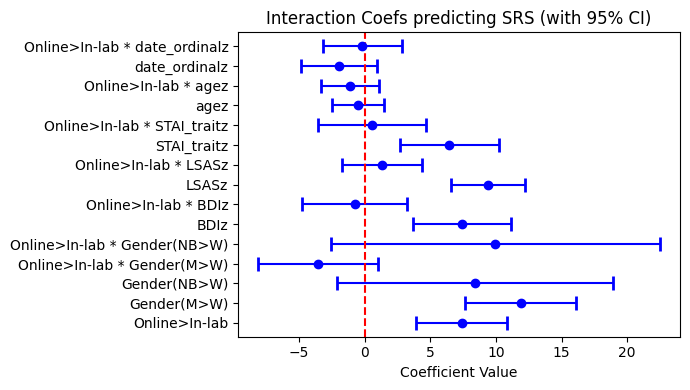

In [32]:
#make summary df before plotting
coef = model_int2.params[1:]
conf_int = model_int2.conf_int()[1:]
results_df_int2 = pd.DataFrame({
    'coef': coef.to_list(),
    'err': ((conf_int.loc[:,1] - conf_int.loc[:, 0]) / 2).to_list(),
    'lower': conf_int.loc[:, 0].to_list(),
    'upper': conf_int.loc[:, 1].to_list()
}, index=['Online>In-lab', 'Gender(M>W)', 'Gender(NB>W)', 'Online>In-lab * Gender(M>W)', 'Online>In-lab * Gender(NB>W)','BDIz','Online>In-lab * BDIz','LSASz', 'Online>In-lab * LSASz', 'STAI_traitz', 'Online>In-lab * STAI_traitz', 'agez', 'Online>In-lab * agez', 'date_ordinalz','Online>In-lab * date_ordinalz'])

#make a plot of the coefficients
fig, ax = plt.subplots(figsize=(7, 4))
y_pos = range(len(results_df_int2))
ax.errorbar(results_df_int2['coef'], y_pos, xerr=results_df_int2['err'], fmt='o', capsize=5, capthick=2, color='blue')
ax.axvline(x=0, color='red', linestyle='--')
ax.set_yticks(y_pos)
ax.set_yticklabels(results_df_int2.index)
ax.set_xlabel('Coefficient Value')
ax.set_title('Interaction Coefs predicting SRS (with 95% CI)')
plt.tight_layout()
plt.show()

# Stability of SRS scores

## Summary of variables

In [33]:
def summary_var_trt(var):
  mean_online = np.mean(t_rt_cutoff.loc[t_rt_cutoff['format']=='Online',var])
  mean_inlab = np.mean(t_rt_cutoff.loc[t_rt_cutoff['format']=='In lab',var])
  sd_online = np.std(t_rt_cutoff.loc[t_rt_cutoff['format']=='Online',var])
  sd_inlab = np.std(t_rt_cutoff.loc[t_rt_cutoff['format']=='In lab',var])
  na_online = np.sum(t_rt_cutoff.loc[t_rt_cutoff['format']=='Online',var].isna())
  na_inlab = np.sum(t_rt_cutoff.loc[t_rt_cutoff['format']=='In lab',var].isna())
  print("Online, mean", var, "=", mean_online, ", SD =", sd_online, ", missing =", na_online)
  print("In-lab, mean", var, "=", mean_inlab, ", SD =", sd_inlab, ", missing =", na_inlab)

Sex

In [34]:
for g in t_rt_cutoff['Sex'].unique().tolist():
  ng = t_rt_cutoff.loc[t_rt_cutoff['format']=='Online','Sex'].tolist().count(g)
  print("Online: Number of", g, "=", ng)

for g in t_rt_cutoff['Sex'].unique().tolist():
  ng = t_rt_cutoff.loc[t_rt_cutoff['format']=='In lab','Sex'].tolist().count(g)
  print("In-lab: Number of", g, "=", ng)

Online: Number of f = 108
Online: Number of m = 95
Online: Number of nan = 0
In-lab: Number of f = 20
In-lab: Number of m = 23
In-lab: Number of nan = 1


Age

In [35]:
summary_var_trt('age_T1')

Online, mean age_T1 = 34.19211822660098 , SD = 11.812890051769086 , missing = 0
In-lab, mean age_T1 = 32.02272727272727 , SD = 8.175597382575996 , missing = 0


Questionnaires

In [36]:
summary_var_trt('SRS_T1')
summary_var_trt('SRS_T2')
summary_var_trt('STAI_trait_T1')
summary_var_trt('STAI_trait_T2')
summary_var_trt('LSAS_T1')
summary_var_trt('LSAS_T2')
summary_var_trt('BDI_T1')
summary_var_trt('BDI_T2')

Online, mean SRS_T1 = 56.76354679802956 , SD = 29.10408112549063 , missing = 0
In-lab, mean SRS_T1 = 37.18181818181818 , SD = 23.480429691817754 , missing = 0
Online, mean SRS_T2 = 55.46305418719212 , SD = 29.848754453009903 , missing = 0
In-lab, mean SRS_T2 = 35.29545454545455 , SD = 23.437130162371286 , missing = 0
Online, mean STAI_trait_T1 = 44.6551724137931 , SD = 13.427026283674664 , missing = 0
In-lab, mean STAI_trait_T1 = 38.121212121212125 , SD = 9.609835793878458 , missing = 11
Online, mean STAI_trait_T2 = 44.18226600985221 , SD = 14.033432311854654 , missing = 0
In-lab, mean STAI_trait_T2 = 37.58064516129032 , SD = 10.609716160346691 , missing = 13
Online, mean LSAS_T1 = 56.75369458128079 , SD = 31.17799564530157 , missing = 0
In-lab, mean LSAS_T1 = 26.757575757575758 , SD = 17.77303081711386 , missing = 11
Online, mean LSAS_T2 = 56.30049261083744 , SD = 31.512502011242553 , missing = 0
In-lab, mean LSAS_T2 = 32.473684210526315 , SD = 25.184306769876045 , missing = 25
Online

Date

In [37]:
t_rt_cutoff['date_T1'] = pd.to_datetime(t_rt_cutoff['date_T1'])
t_rt_cutoff['date_T2'] = pd.to_datetime(t_rt_cutoff['date_T2'])
t_rt_cutoff[t_rt_cutoff['format']=='Online']['date_T1'].dt.year.value_counts()

/var/folders/5q/slj33l6j3t3bg7dm3cbt6r500000gn/T/ipykernel_86046/2629135932.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  t_rt_cutoff['date_T1'] = pd.to_datetime(t_rt_cutoff['date_T1'])
/var/folders/5q/slj33l6j3t3bg7dm3cbt6r500000gn/T/ipykernel_86046/2629135932.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  t_rt_cutoff['date_T2'] = pd.to_datetime(t_rt_cutoff['date_T2'])


date_T1
2021    134
2020     69
Name: count, dtype: int64

In [38]:
t_rt_cutoff[t_rt_cutoff['format']=='In lab']['date_T1'].dt.year.value_counts()

date_T1
2021    14
2020    11
2015     7
2014     4
2022     4
2019     3
2023     1
Name: count, dtype: int64

## Correlations between T1 and T2 SRS scores

Text(0.5, 1.0, 'R = 0.76')

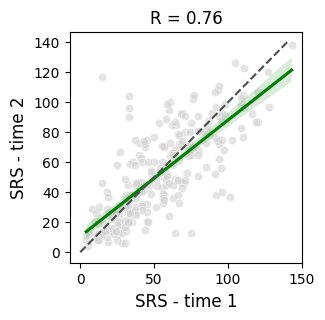

In [39]:
#plot correlation
fig, ax = plt.subplots(figsize=(3,3))
sns.scatterplot(data=t_rt_cutoff, x='SRS_T1',  y='SRS_T2', color = 'lightgrey', alpha=0.6)
sns.regplot(data=t_rt_cutoff, x='SRS_T1', y='SRS_T2', scatter=False, color='green')
ax.plot([0, 140], [0, 140], ls='--', c='0.3')
ax.set_xlabel('SRS - time 1', fontsize = 12)
ax.set_ylabel('SRS - time 2', fontsize = 12)
r_value, p_value = pearsonr(t_rt_cutoff['SRS_T1'], t_rt_cutoff['SRS_T2'])
ax.set_title(f'R = {r_value:.2f}')

In [40]:
#paired t-test between time 1 and time 2
print("N =", len(t_rt_cutoff))
print(np.mean(t_rt_cutoff['SRS_T1']))
print(np.mean(t_rt_cutoff['SRS_T2']))
ttest_rel(t_rt_cutoff['SRS_T1'], t_rt_cutoff['SRS_T2'])

N = 247
53.2753036437247
51.87044534412956


TtestResult(statistic=np.float64(1.0732457325763616), pvalue=np.float64(0.28421253404348074), df=np.int64(246))

In [41]:
# broken down by format
r1, p1 = pearsonr(t_rt_cutoff[t_rt_cutoff['format'] == 'Online']['SRS_T1'], t_rt_cutoff[t_rt_cutoff['format'] == 'Online']['SRS_T2'])
r2, p2 = pearsonr(t_rt_cutoff[t_rt_cutoff['format'] == 'In lab']['SRS_T1'], t_rt_cutoff[t_rt_cutoff['format'] == 'In lab']['SRS_T2'])
n1 = np.sum(t_rt_cutoff['format'] == 'Online')
n2 = np.sum(t_rt_cutoff['format'] == 'In lab')
print(f'Online, N = {n1}, R = {r1:.2f}, P = {p1:.3f}')
print(f'In lab, N = {n2}, R = {r2:.2f}, P = {p2:.3f}')

Online, N = 203, R = 0.73, P = 0.000
In lab, N = 44, R = 0.80, P = 0.000


In [42]:
#check whether the two correlations are different
z1 = 0.5 * np.log((1 + r1) / (1 - r1))
z2 = 0.5 * np.log((1 + r2) / (1 - r2))
se = np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
z_stat = (z1 - z2) / se
p_value = 2 * (1 - norm.cdf(abs(z_stat)))
print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: -1.0045425411249163
P-value: 0.31511717689988905


## Differences in SRS stability driven by specific SRS items/subscales/factors?


In [43]:
def cohens_d_paired(x, y):
    """
    Calculate Cohen's d for paired samples.
    Parameters:
    x: First set of observations
    y: Second set of observations
    Returns:
    Cohen's d
    """
    diff = np.array(y) - np.array(x)
    mean_diff = np.mean(diff)
    std_diff = np.std(diff, ddof=1)  # Use ddof=1 for unbiased standard deviation
    return mean_diff / std_diff

In [44]:
item_names = []
mean_item_T1 = []
mean_item_T2 = []
mean_item_diff = []
t_stat_all = []
p_value_all = []
d_all = []
reverse_coded_fields = ['SRS_3', 'SRS_7', 'SRS_11', 'SRS_12', 'SRS_15', 'SRS_17', 'SRS_21', 'SRS_22', 'SRS_26', 'SRS_32', 'SRS_38', 'SRS_40', 'SRS_43', 'SRS_45', 'SRS_48']

for n in range(1,66):
  col_name = 'SRS_'+ str(n)
  col_name_T1 = col_name + '_T1'
  col_name_T2 = col_name + '_T2'
  if col_name in reverse_coded_fields:
    sample1 = 3-t_rt_cutoff[col_name_T1]
    sample2 = 3-t_rt_cutoff[col_name_T2]
  else:
    sample1 = t_rt_cutoff[col_name_T1]
    sample2 = t_rt_cutoff[col_name_T2]

  diff = sample2 - sample1
  t_stat, p_value = ttest_rel(sample1, sample2)
  d = cohens_d_paired(sample1, sample2)

  item_names.append(col_name)
  mean_item_T1.append(np.mean(sample1))
  mean_item_T2.append(np.mean(sample2))
  mean_item_diff.append(np.mean(diff))
  t_stat_all.append(t_stat)
  p_value_all.append(p_value)
  d_all.append(d)

df_item_trt_cutoff = pd.DataFrame(data = {'SRS_item': item_names, 'T1 mean': mean_item_T1, 'T2 mean': mean_item_T2, 'diff_mean': mean_item_diff,
                                    'T': t_stat_all, 'p': p_value_all, 'd': d_all})

In [45]:
df_item_trt_cutoff = pd.merge(df_item_trt_cutoff, SRS_item_description, on='SRS_item', how='left')
df_item_trt_cutoff = df_item_trt_cutoff.drop(columns=['index'])
df_item_trt_cutoff_pord = df_item_trt_cutoff.sort_values(by='p', ascending=True).reset_index(drop=True)
for n in range(1,66):
  df_item_trt_cutoff_pord.loc[n-1,'pFDR'] = 0.05 * n / 65
  df_item_trt_cutoff_pord.loc[n-1,'isSigFDR'] = df_item_trt_cutoff_pord.loc[n-1,'p'] <= df_item_trt_cutoff_pord.loc[n-1,'pFDR']
df_item_trt_cutoff_pord

,SRS_item,T1 mean,T2 mean,diff_mean,T,p,d,question_text,subscale,is_rev,Factor_simplified,Factor_OLpaper,pFDR,isSigFDR
0,SRS_21,1.352227,1.056680,-0.295547,4.576328,0.000008,-0.291185,I am able to imitate others\ actions and expre...,com,yes,3,3,0.000769,True
1,SRS_26,1.064777,0.947368,-0.117409,2.503927,0.012931,-0.159321,I offer comfort to others when they are sad.,com,yes,3,3,0.001538,False
2,SRS_1,1.303644,1.510121,0.206478,-2.494007,0.013289,0.158690,I am much more uncomfortable in social situati...,mot,no,2,2,0.002308,False
3,SRS_55,0.307692,0.190283,-0.117409,2.449525,0.015003,-0.155860,I get too close to others or invade their pers...,com,no,<NA>,1,0.003077,False
4,SRS_12,1.259109,1.153846,-0.105263,2.138185,0.033487,-0.136049,I am able to communicate my feelings to others.,com,yes,<NA>,4,0.003846,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,SRS_39,0.457490,0.453441,-0.004049,0.075441,0.939925,-0.004800,People think I am interested in too few topics...,rrb,no,1,1,0.046923,False
61,SRS_43,1.813765,1.817814,0.004049,-0.072980,0.941881,0.004644,I enjoy small talk (casual conversation with o...,mot,yes,<NA>,2,0.047692,False
62,SRS_57,1.238866,1.234818,-0.004049,0.070045,0.944215,-0.004457,I tend to isolate myself.,com,no,2,2,0.048462,False
63,SRS_29,0.724696,0.724696,0.000000,0.000000,1.000000,0.000000,I am regarded by others as odd or weird.,rrb,no,<NA>,7,0.049231,False


In [65]:
#save data
df_item_trt_cutoff_pord.to_csv(root + '/results/item_T1_T2_diff_data.csv')

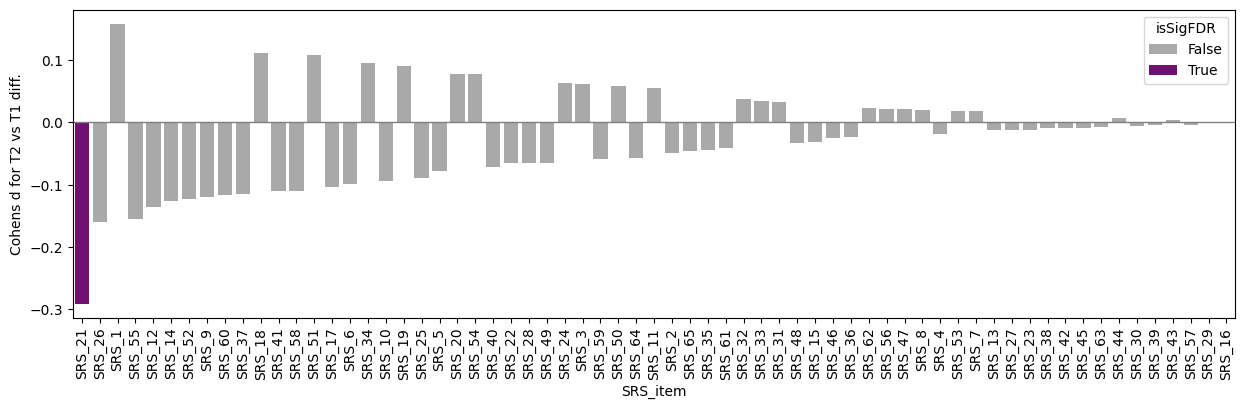

In [46]:
plt.figure(figsize=(15, 4))
my_colors = sns.color_palette(["darkgrey", "purple"])
sns.barplot(x='SRS_item', y='d', hue='isSigFDR', palette = my_colors, data = df_item_trt_cutoff_pord)
plt.axhline(y=0, color='grey', linewidth=1)
plt.ylabel('Cohens d for T2 vs T1 diff.')
plt.xticks(rotation=90)
plt.show()

## Item-by-item ICC correlates with item score differences between online and in-lab

In [47]:
#data from variability analyses summarizing item-by-item differences between in-lab and online
df_item_diff['diff_online_inlab'] = df_item_diff['Online mean'] - df_item_diff['In lab mean']
df_item_diff['abs_diff'] = np.abs(df_item_diff['diff_online_inlab'])
df_item_diff.sort_values(by='SRS_item', ascending=True, inplace=True)

In [48]:
#load item-wise ICC data
ICC_all = ICC_all[~ICC_all['variable'].isin(['SRS','SRS_AWR','SRS_COG','SRS_COM','SRS_MOT','SRS_RRB'])]
ICC_all.rename(columns={'variable': 'SRS_item', 'ICC':'ICC_all'}, inplace=True)
ICC_all = ICC_all[['SRS_item', 'ICC_all']]
# combine the data
df_item_diff = df_item_diff.merge(ICC_all, on='SRS_item', how='left')
df_item_diff.head()

,SRS_item,In lab mean,Online mean,T,df,p,Cohens_d,Cohens_d_rev,question_text,subscale,is_rev,Factor_simplified,Factor_OLpaper,pFDR,isSigFDR,diff_online_inlab,abs_diff,ICC_all
0,SRS_1,1.578045,1.040486,11.176919,771.385026,5.505404e-27,0.518111,0.518111,I am much more uncomfortable in social situati...,mot,no,2,2,0.003846,True,-0.537559,0.537559,0.257496
1,SRS_10,0.798885,0.536437,6.640253,776.894147,5.881113e-11,0.305987,0.305987,"I take things too literally, and because of th...",cog,no,1,1,0.030000,True,-0.262448,0.262448,0.363962
2,SRS_11,1.422384,1.714575,-6.276789,751.735697,5.837699e-10,-0.297522,0.297522,I have good self-confidence.,mot,yes,4,4,0.035385,True,0.292191,0.292191,0.670664
3,SRS_12,1.659091,1.931174,-6.505063,732.554053,1.438364e-10,-0.315696,0.315696,I am able to communicate my feelings to others.,com,yes,<NA>,4,0.031538,True,0.272083,0.272083,0.628099
4,SRS_13,0.907804,0.578947,7.881908,789.243833,1.069970e-14,0.358553,0.358553,I am awkward in turn-taking interactions with ...,com,no,5,5,0.019231,True,-0.328857,0.328857,0.475204


Check correlations and make plots

Text(0.5, 1.0, 'R = 0.36, P = 0.003')

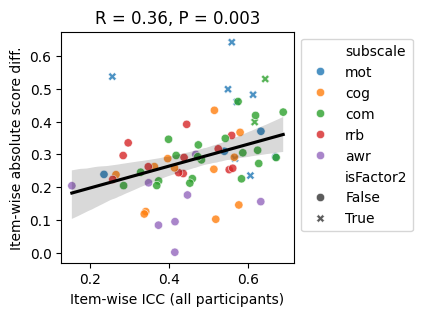

In [49]:
#correlation between ICC_all and abs_diff_online_inlab
df_item_diff['isFactor2'] = df_item_diff['Factor_OLpaper'].apply(lambda x: True if x == 2 else False)
fig, ax = plt.subplots(figsize=(3,3))
sns.scatterplot(data=df_item_diff, x='ICC_all',  y='abs_diff', hue = 'subscale', style='isFactor2', alpha=0.8)
sns.regplot(data=df_item_diff, x='ICC_all', y='abs_diff', scatter=False, color='black')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_xlabel('Item-wise ICC (all participants)', fontsize = 10)
ax.set_ylabel('Item-wise absolute score diff.', fontsize = 10)
r_value, p_value = pearsonr(df_item_diff['ICC_all'], df_item_diff['abs_diff'])
ax.set_title(f'R = {r_value:.2f}, P = {p_value:.3f}')

## Individual differences contributing to the SRS stability

In [50]:
t_rt_cutoff['SRS_diff_abs'] = np.abs(t_rt_cutoff['SRS_T2'] - t_rt_cutoff['SRS_T1'])
t_rt_cutoff['date_ordinal_T1_z'] = zscore(t_rt_cutoff['date_ordinal_T1'].astype(float))
t_rt_cutoff['date_ordinal_T2_z'] = zscore(t_rt_cutoff['date_ordinal_T2'].astype(float))
t_rt_cutoff['T2_T1_diff'] = t_rt_cutoff['date_ordinal_T2'] - t_rt_cutoff['date_ordinal_T1']
t_rt_cutoff['T2_T1_diff_z'] = zscore(t_rt_cutoff['T2_T1_diff'].astype(float))
t_rt_cutoff['BDI_diff_abs'] = np.abs(t_rt_cutoff['BDI_T2'] - t_rt_cutoff['BDI_T1'])
t_rt_cutoff['LSAS_diff_abs'] = np.abs(t_rt_cutoff['LSAS_T2'] - t_rt_cutoff['LSAS_T1'])
t_rt_cutoff['STAI_trait_diff_abs'] = np.abs(t_rt_cutoff['STAI_trait_T2'] - t_rt_cutoff['STAI_trait_T1'])

df_glm_trt_cutoff = t_rt_cutoff[['SRS_diff_abs', 'format', 'Sex', 'age_T1', 'BDI_diff_abs', 'LSAS_diff_abs', 'STAI_trait_diff_abs',
                       'SRS_T1', 'date_ordinal_T1_z','T2_T1_diff_z']].dropna()


#glm
model_trt_cutoff = smf.ols('SRS_diff_abs ~ format + Sex + scale(age_T1) + scale(BDI_diff_abs) + scale(LSAS_diff_abs) + scale(STAI_trait_diff_abs) + \
                    scale(SRS_T1) + date_ordinal_T1_z + T2_T1_diff_z', data=df_glm_trt_cutoff).fit()

#make summary df before plotting
coef = model_trt_cutoff.params[1:]
conf_int = model_trt_cutoff.conf_int()[1:]
glm_sta_abs_results = pd.DataFrame({
    'coef': coef.to_list(),
    'err': ((conf_int.loc[:,1] - conf_int.loc[:, 0]) / 2).to_list(),
    'lower': conf_int.loc[:, 0].to_list(),
    'upper': conf_int.loc[:, 1].to_list()
}, index=['Online>In-lab', 'Sex(m>f)', 'Age T1','BDI |T2 - T1|','LSAS |T2 - T1|','STAI-T |T2 - T1|','SRS T1','Date T1','Time interval'])

In [51]:
glm_sta_abs_results

,coef,err,lower,upper
Online>In-lab,15.771515,29.685122,-13.913607,45.456638
Sex(m>f),1.941564,3.650717,-1.709153,5.592282
Age T1,-0.818533,1.918012,-2.736545,1.099479
BDI |T2 - T1|,-0.206834,2.262565,-2.469399,2.055731
LSAS |T2 - T1|,3.852165,1.838536,2.013629,5.690701
STAI-T |T2 - T1|,5.380338,2.145732,3.234606,7.526071
SRS T1,1.031588,1.947677,-0.916090,2.979265
Date T1,-9.975755,18.687542,-28.663297,8.711788
Time interval,-5.132243,13.841112,-18.973355,8.708869
